# Music DT Probe Results

6개 downstream task에 대한 linear probe 결과를 확인합니다. 위쪽은 각 모델의 final embedding만, 아래쪽은 intermediate layer까지 모두 포함한 결과입니다.

- 바꿔야 하는 설정은 `ALIGNMENT_KIND` 하나뿐입니다.
- `ALIGNMENT_KIND = 'rsa'` 또는 `ALIGNMENT_KIND = 'regression'`

In [1]:
import os
import sys
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib')

try:
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    import seaborn as sns
    from IPython.display import Markdown, display
    from scipy.stats import pearsonr, spearmanr
except ModuleNotFoundError as exc:
    raise RuntimeError(
        'Notebook dependencies are missing in the current kernel. '
        'Please run Jupyter from the universal conda environment or switch the kernel to that environment. '
        f'Current executable: {sys.executable}'
    ) from exc

ROOT = Path('/home/hjkim/selective_auditory/ismir2026/music_task_probe')
RESULT_ROOT = ROOT / 'probe_results'
FINAL_RESULT_ROOT = ROOT / 'probe_results_final_only'
EMBED_ROOT = Path('/home/hjkim/selective_auditory/ismir2026/music_task_embed/embeddings')

ALIGNMENT_KIND = 'rsa'  # 'rsa' or 'regression'
ALIGNMENT_DATASET = 'mean'

summary = pd.read_csv(RESULT_ROOT / 'probe_summary.csv')
details = pd.read_csv(RESULT_ROOT / 'probe_details.csv')
alignment = pd.read_csv(RESULT_ROOT / 'alignment_layerwise.csv')
merged_layerwise = pd.read_csv(RESULT_ROOT / 'probe_alignment_layerwise_merged.csv')
summary_final_complete = pd.read_csv(FINAL_RESULT_ROOT / 'probe_summary.csv')
merged_final = pd.read_csv(FINAL_RESULT_ROOT / 'probe_alignment_layerwise_merged.csv')

task_order = [
    'GTZAN / genre_classification',
    'VocalSet / singing_technique',
    'EMO / emotion_regression',
    'NSynthPitch5h / pitch_estimation',
    'MagnaTagATune / music_tagging',
    'GiantSteps / key_detection',
]
model_order = ['clap', 'mulan', 'mert']
palette = {'clap': '#1b9e77', 'mulan': '#d95f02', 'mert': '#7570b3'}

for frame in (summary, details, merged_layerwise, summary_final_complete, merged_final):
    frame['dataset_task'] = frame['dataset_name'] + ' / ' + frame['task_name']
    frame['dataset_task'] = pd.Categorical(frame['dataset_task'], categories=task_order, ordered=True)
    frame['model_name'] = pd.Categorical(frame['model_name'], categories=model_order, ordered=True)

summary['layer_order'] = summary['layer_index'].fillna(1e9)
merged_layerwise['layer_order'] = merged_layerwise['layer_index'].fillna(1e9)

plot_final = merged_final[(merged_final['alignment_kind'] == ALIGNMENT_KIND) & (merged_final['alignment_dataset'] == ALIGNMENT_DATASET)].copy()
plot_layerwise = merged_layerwise[(merged_layerwise['alignment_kind'] == ALIGNMENT_KIND) & (merged_layerwise['alignment_dataset'] == ALIGNMENT_DATASET)].copy()
score_label = plot_final['alignment_score_name'].iloc[0] if len(plot_final) else 'alignment_score'

sns.set_theme(context='notebook', style='whitegrid')
print({'alignment_kind': ALIGNMENT_KIND, 'alignment_dataset': ALIGNMENT_DATASET, 'n_final_rows': int(len(plot_final)), 'n_layerwise_rows': int(len(plot_layerwise))})

{'alignment_kind': 'rsa', 'alignment_dataset': 'mean', 'n_final_rows': 18, 'n_layerwise_rows': 276}


In [2]:
task_specs = [
    ('gtzan', 'genre_classification', 'GTZAN'),
    ('vocalset', 'singing_technique', 'VocalSet'),
    ('emo', 'emotion_regression', 'EMO'),
    ('nsynthpitch5h', 'pitch_estimation', 'NSynthPitch5h'),
    ('magnatagatune', 'music_tagging', 'MagnaTagATune'),
    ('giantsteps', 'key_detection', 'GiantSteps'),
]
expected_reps = {'clap': 6, 'mulan': 14, 'mert': 26}

status_rows = []
for dataset_dir, task_dir, display_name in task_specs:
    expected_parts = 5 if dataset_dir == 'vocalset' else 3
    for model_name in model_order:
        model_root = EMBED_ROOT / dataset_dir / task_dir / model_name
        rep_dirs = sorted([p for p in model_root.iterdir() if p.is_dir()]) if model_root.exists() else []
        complete_reps = [rep for rep in rep_dirs if len(list(rep.glob('*.npz'))) == expected_parts]
        status_rows.append({
            'dataset_task': f'{display_name} / {task_dir}',
            'model_name': model_name,
            'complete_representations': len(complete_reps),
            'expected_representations': expected_reps[model_name],
            'complete': len(complete_reps) == expected_reps[model_name],
        })

status = pd.DataFrame(status_rows)
display(Markdown('### Embedding readiness'))
display(status.pivot(index='dataset_task', columns='model_name', values='complete_representations').reindex(index=task_order, columns=model_order))

if not bool(status['complete'].all()):
    display(Markdown('**NaN이 보이면 대부분 probe가 아직 덜 끝난 상태입니다.** metric 자체가 NaN이라기보다, 해당 task/model 결과 row가 아직 CSV에 안 들어와서 생기는 경우가 대부분입니다.'))

### Embedding readiness

model_name,clap,mulan,mert
dataset_task,,,
GTZAN / genre_classification,6,14,26
VocalSet / singing_technique,6,14,26
EMO / emotion_regression,6,14,26
NSynthPitch5h / pitch_estimation,6,14,26
MagnaTagATune / music_tagging,6,14,26
GiantSteps / key_detection,6,14,26


In [3]:
display(Markdown('### Final-layer metric table'))
final_summary = summary_final_complete.copy()
final_metric_table = final_summary.pivot(index='dataset_task', columns='model_name', values='primary_metric_value').reindex(index=task_order, columns=model_order)
display(final_metric_table.style.format('{:.4f}').background_gradient(cmap='YlGn'))

display(Markdown('### Best available layer per task/model'))
best_layers = (
    summary.dropna(subset=['primary_metric_value'])
    .sort_values(['dataset_task', 'model_name', 'primary_metric_value', 'layer_order'], ascending=[True, True, False, True])
    .groupby(['dataset_task', 'model_name'], as_index=False, observed=True)
    .first()[['dataset_task', 'model_name', 'representation_name', 'primary_metric_name', 'primary_metric_value']]
)
display(best_layers)
if len(best_layers) < len(task_order) * len(model_order):
    display(Markdown('**Note:** layer-wise probe가 아직 진행 중이라 일부 task/model의 best layer row는 아직 비어 있습니다.'))

### Final-layer metric table

model_name,clap,mulan,mert
dataset_task,,,
GTZAN / genre_classification,0.7103,0.8586,0.6483
VocalSet / singing_technique,0.7090,0.7848,0.7123
EMO / emotion_regression,0.6718,0.8054,0.6041
NSynthPitch5h / pitch_estimation,0.0720,0.0660,0.0660
MagnaTagATune / music_tagging,0.4458,0.4721,0.4304
GiantSteps / key_detection,0.0810,0.3292,0.3894


### Best available layer per task/model

,dataset_task,model_name,representation_name,primary_metric_name,primary_metric_value
0,GTZAN / genre_classification,clap,audio_embedding,accuracy,0.710345
1,GTZAN / genre_classification,mulan,layer_11,accuracy,0.865517
2,GTZAN / genre_classification,mert,layer_09,accuracy,0.727586
3,VocalSet / singing_technique,clap,layer_03,accuracy,0.764053
4,VocalSet / singing_technique,mulan,layer_08,accuracy,0.851458
5,VocalSet / singing_technique,mert,layer_06,accuracy,0.794984
6,EMO / emotion_regression,clap,layer_02,pearson_mean,0.678567
7,EMO / emotion_regression,mulan,final,pearson_mean,0.805387
8,EMO / emotion_regression,mert,layer_04,pearson_mean,0.674157
9,NSynthPitch5h / pitch_estimation,clap,layer_04,rounded_accuracy,0.078000


### Final-layer correlation and plots

,dataset_task,n_points,pearson_r,spearman_rho
0,ALL_TASKS,18,-0.053535,0.045926
1,GTZAN / genre_classification,3,0.210186,0.500000
2,VocalSet / singing_technique,3,-0.117893,-0.500000
3,EMO / emotion_regression,3,0.254737,0.500000
4,NSynthPitch5h / pitch_estimation,3,0.902993,0.866025
5,MagnaTagATune / music_tagging,3,0.290343,0.500000
6,GiantSteps / key_detection,3,-0.966723,-1.000000


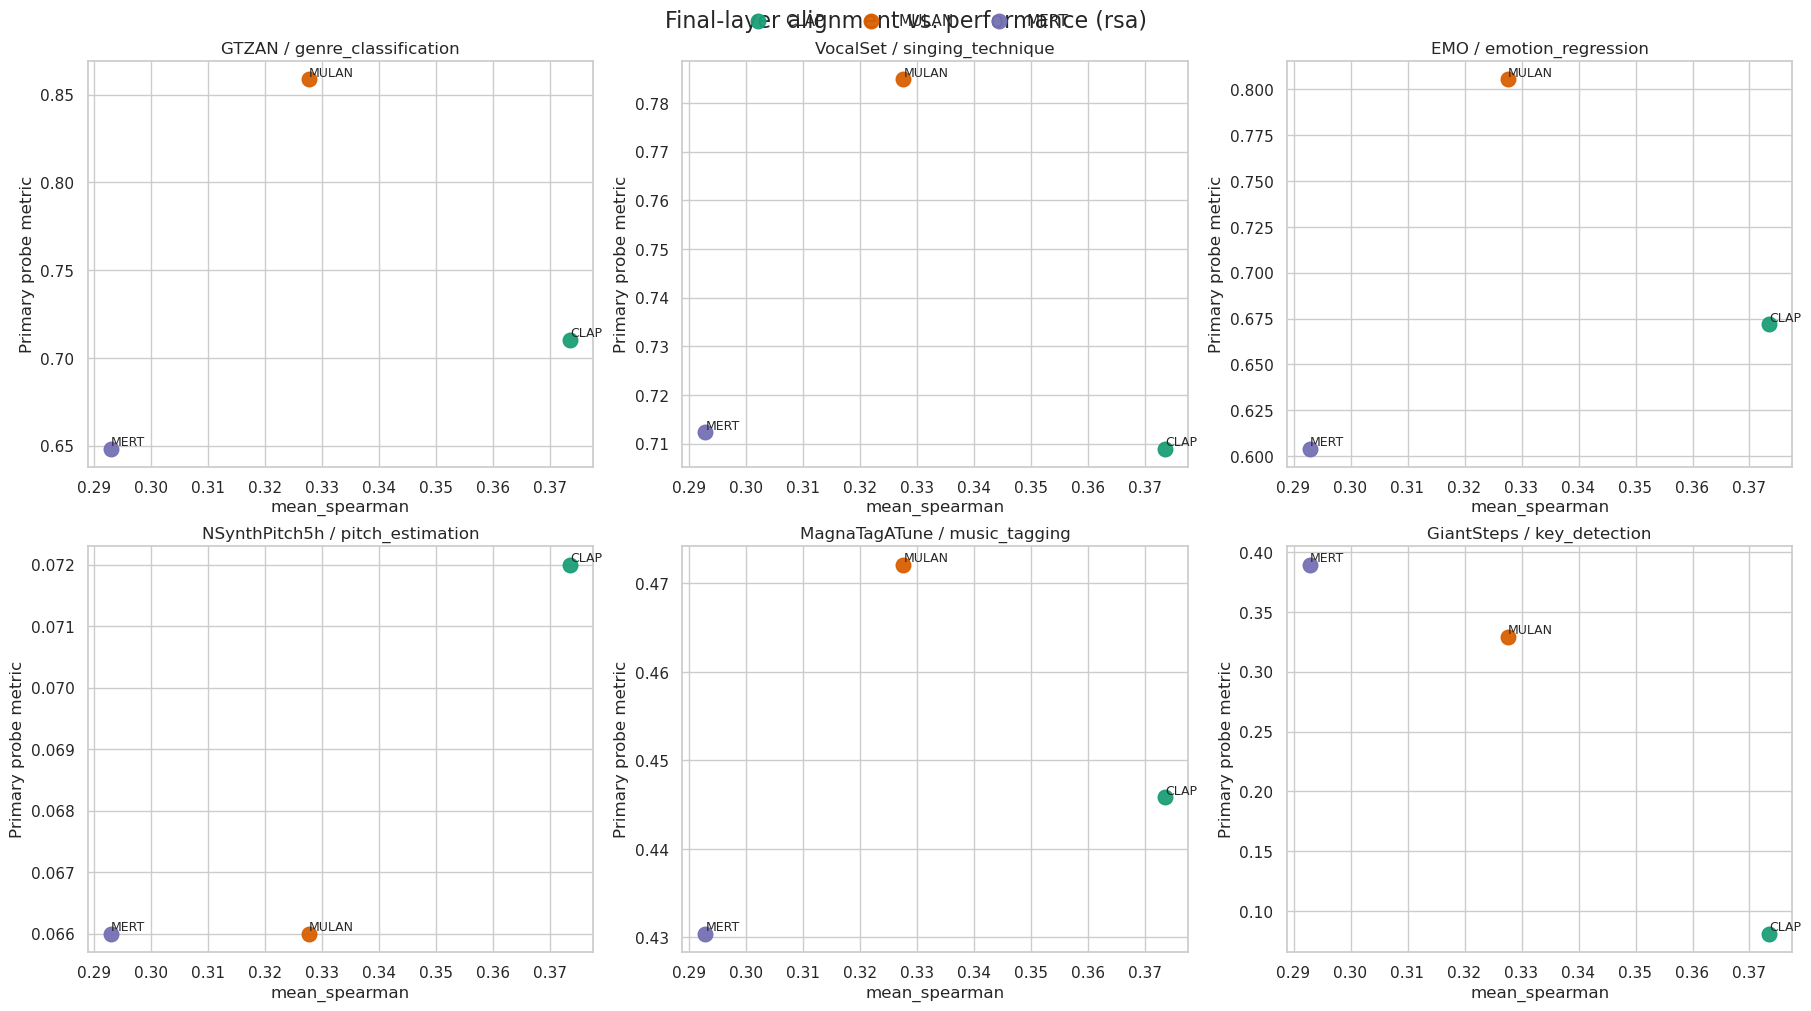

In [4]:
display(Markdown('### Final-layer correlation and plots'))
corr_rows = []
if len(plot_final) >= 3:
    corr_rows.append({
        'dataset_task': 'ALL_TASKS',
        'n_points': int(len(plot_final)),
        'pearson_r': float(pearsonr(plot_final['alignment_score'], plot_final['primary_metric_value']).statistic),
        'spearman_rho': float(spearmanr(plot_final['alignment_score'], plot_final['primary_metric_value']).statistic),
    })
for dataset_task in task_order:
    subset = plot_final[plot_final['dataset_task'] == dataset_task]
    if len(subset) < 3:
        continue
    corr_rows.append({
        'dataset_task': dataset_task,
        'n_points': int(len(subset)),
        'pearson_r': float(pearsonr(subset['alignment_score'], subset['primary_metric_value']).statistic),
        'spearman_rho': float(spearmanr(subset['alignment_score'], subset['primary_metric_value']).statistic),
    })
display(pd.DataFrame(corr_rows))

fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True)
axes = axes.ravel()
for ax, dataset_task in zip(axes, task_order):
    subset = plot_final[plot_final['dataset_task'] == dataset_task].copy().sort_values(['model_name'])
    for model_name in model_order:
        model_subset = subset[subset['model_name'] == model_name]
        if len(model_subset) == 0:
            continue
        ax.scatter(
            model_subset['alignment_score'],
            model_subset['primary_metric_value'],
            color=palette[model_name],
            s=110,
            alpha=0.95,
            label=model_name.upper(),
        )
        for _, row in model_subset.iterrows():
            ax.text(row['alignment_score'], row['primary_metric_value'], model_name.upper(), fontsize=9, ha='left', va='bottom')
    ax.set_title(dataset_task)
    ax.set_xlabel(score_label)
    ax.set_ylabel('Primary probe metric')

handles, labels = axes[0].get_legend_handles_labels()
unique = dict(zip(labels, handles))
if unique:
    fig.legend(unique.values(), unique.keys(), loc='upper center', ncol=3, frameon=False)
fig.suptitle(f'Final-layer alignment vs. performance ({ALIGNMENT_KIND})', fontsize=16)
plt.show()

### Layer-wise correlation and plots

,dataset_task,n_points,pearson_r,pearson_p,spearman_rho,spearman_p
0,ALL_TASKS,276,0.154891,9.962384e-03,0.160235,7.648561e-03
1,GTZAN / genre_classification,46,0.597433,1.168281e-05,0.425200,3.222453e-03
2,VocalSet / singing_technique,46,0.707140,3.941872e-08,0.710991,3.080263e-08
3,EMO / emotion_regression,46,0.343022,1.960809e-02,0.338226,2.150216e-02
4,NSynthPitch5h / pitch_estimation,46,0.499313,4.116337e-04,0.434080,2.578153e-03
5,MagnaTagATune / music_tagging,46,0.592736,1.423344e-05,0.571111,3.399404e-05
6,GiantSteps / key_detection,46,0.408671,4.806230e-03,0.635952,2.040803e-06


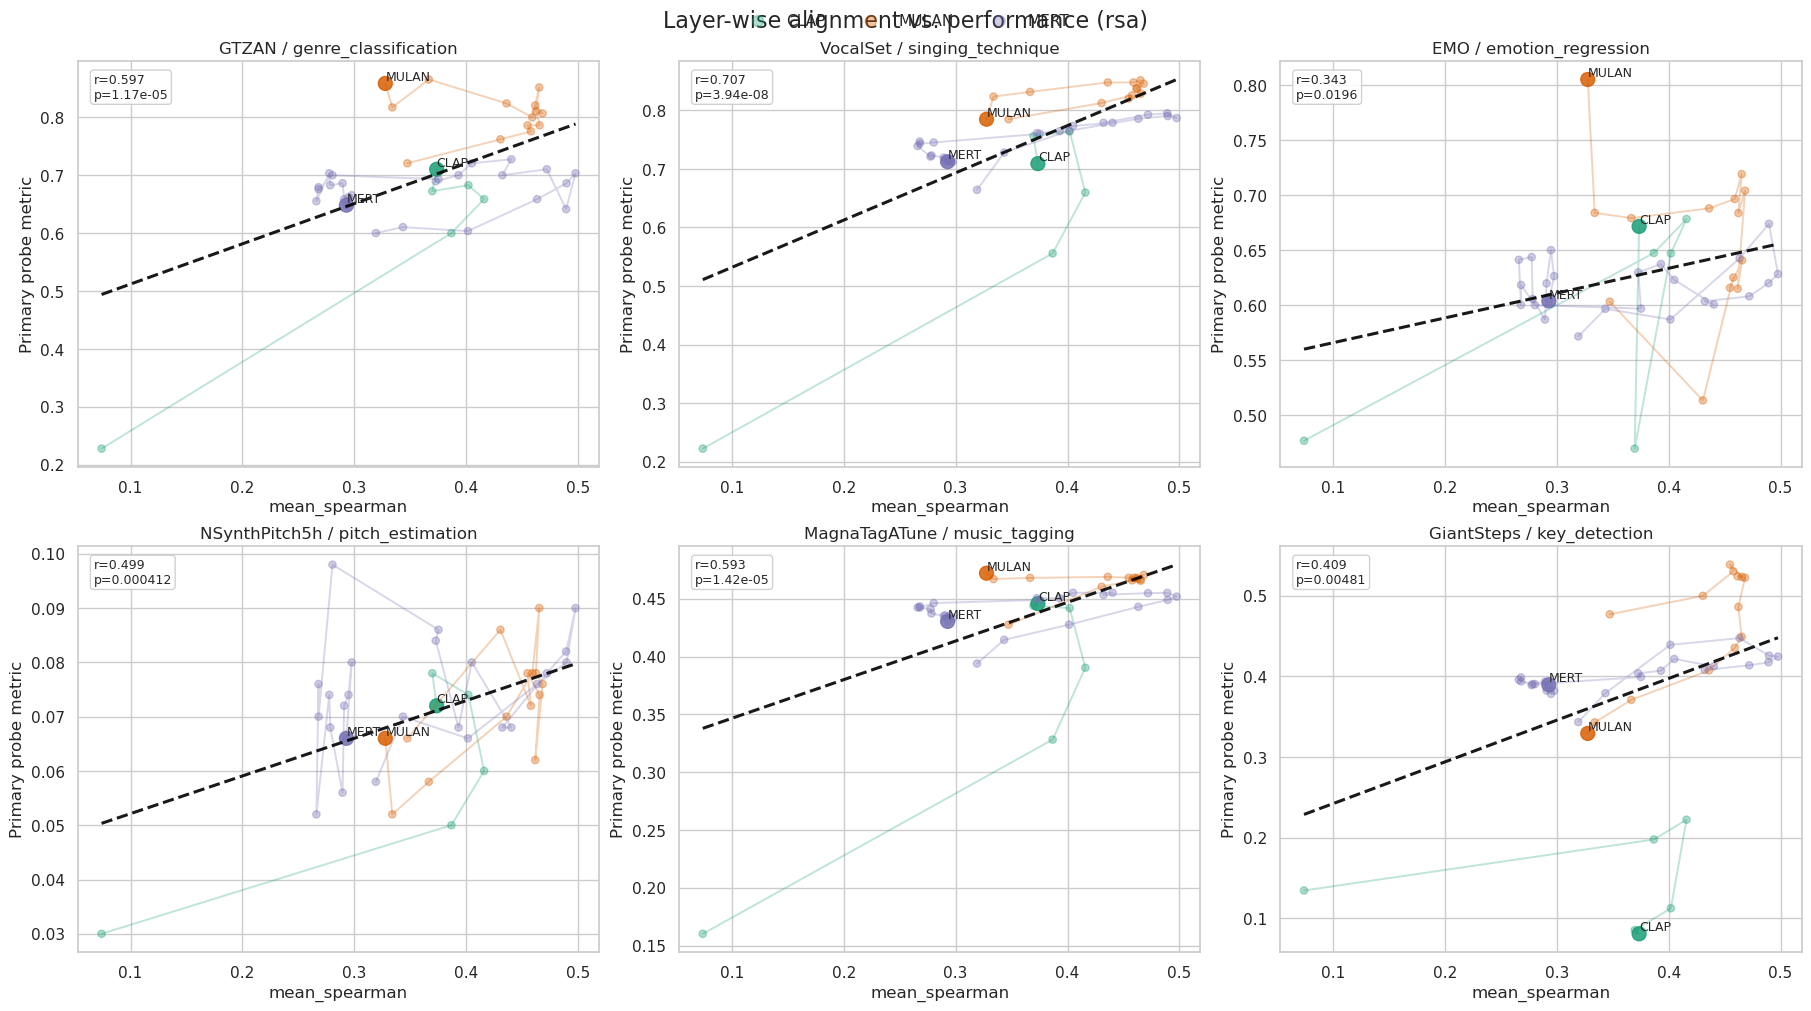

In [5]:
display(Markdown('### Layer-wise correlation and plots'))
corr_rows = []
if len(plot_layerwise) >= 3:
    pearson_all = pearsonr(plot_layerwise['alignment_score'], plot_layerwise['primary_metric_value'])
    spearman_all = spearmanr(plot_layerwise['alignment_score'], plot_layerwise['primary_metric_value'])
    corr_rows.append({
        'dataset_task': 'ALL_TASKS',
        'n_points': int(len(plot_layerwise)),
        'pearson_r': float(pearson_all.statistic),
        'pearson_p': float(pearson_all.pvalue),
        'spearman_rho': float(spearman_all.statistic),
        'spearman_p': float(spearman_all.pvalue),
    })
for dataset_task in task_order:
    subset = plot_layerwise[plot_layerwise['dataset_task'] == dataset_task]
    if len(subset) < 3:
        continue
    pearson_task = pearsonr(subset['alignment_score'], subset['primary_metric_value'])
    spearman_task = spearmanr(subset['alignment_score'], subset['primary_metric_value'])
    corr_rows.append({
        'dataset_task': dataset_task,
        'n_points': int(len(subset)),
        'pearson_r': float(pearson_task.statistic),
        'pearson_p': float(pearson_task.pvalue),
        'spearman_rho': float(spearman_task.statistic),
        'spearman_p': float(spearman_task.pvalue),
    })
display(pd.DataFrame(corr_rows))

fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True)
axes = axes.ravel()
for ax, dataset_task in zip(axes, task_order):
    subset = plot_layerwise[plot_layerwise['dataset_task'] == dataset_task].copy().sort_values(['model_name', 'layer_order'])
    for model_name in model_order:
        model_subset = subset[subset['model_name'] == model_name]
        if len(model_subset) == 0:
            continue
        ax.plot(
            model_subset['alignment_score'],
            model_subset['primary_metric_value'],
            color=palette[model_name],
            linewidth=1.4,
            alpha=0.28,
        )
        ax.scatter(
            model_subset['alignment_score'],
            model_subset['primary_metric_value'],
            color=palette[model_name],
            s=np.where(model_subset['is_final'], 100, 28),
            alpha=np.where(model_subset['is_final'], 0.85, 0.35),
            label=model_name.upper(),
        )
        final_points = model_subset[model_subset['is_final']]
        for _, row in final_points.iterrows():
            ax.text(row['alignment_score'], row['primary_metric_value'], model_name.upper(), fontsize=9, ha='left', va='bottom')
    if len(subset) >= 3:
        x = subset['alignment_score'].to_numpy()
        y = subset['primary_metric_value'].to_numpy()
        slope, intercept = np.polyfit(x, y, deg=1)
        x_line = np.linspace(float(np.min(x)), float(np.max(x)), 100)
        y_line = slope * x_line + intercept
        pearson_task = pearsonr(x, y)
        ax.plot(x_line, y_line, color='black', linestyle='--', linewidth=2.2, alpha=0.9)
        ax.text(
            0.03,
            0.97,
            f"r={pearson_task.statistic:.3f}\np={pearson_task.pvalue:.3g}",
            transform=ax.transAxes,
            ha='left',
            va='top',
            fontsize=9,
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='0.8', alpha=0.9),
        )
    ax.set_title(dataset_task)
    ax.set_xlabel(score_label)
    ax.set_ylabel('Primary probe metric')

handles, labels = axes[0].get_legend_handles_labels()
unique = dict(zip(labels, handles))
if unique:
    fig.legend(unique.values(), unique.keys(), loc='upper center', ncol=3, frameon=False)
fig.suptitle(f'Layer-wise alignment vs. performance ({ALIGNMENT_KIND})', fontsize=16)
plt.show()

### Layer-wise correlation after outlier trimming

,dataset_task,n_before,n_after,n_removed
0,GTZAN / genre_classification,46,45,1
1,VocalSet / singing_technique,46,44,2
2,EMO / emotion_regression,46,41,5
3,NSynthPitch5h / pitch_estimation,46,44,2
4,MagnaTagATune / music_tagging,46,43,3
5,GiantSteps / key_detection,46,35,11


,dataset_task,n_points,pearson_r,pearson_p,spearman_rho,spearman_p
0,ALL_TASKS,252,0.072488,2.515910e-01,0.139100,2.725082e-02
1,GTZAN / genre_classification,45,0.378318,1.039379e-02,0.385987,8.824832e-03
2,VocalSet / singing_technique,44,0.681604,3.515453e-07,0.714145,5.235717e-08
3,EMO / emotion_regression,41,0.348476,2.555985e-02,0.332346,3.375361e-02
4,NSynthPitch5h / pitch_estimation,44,0.433660,3.273953e-03,0.474153,1.148192e-03
5,MagnaTagATune / music_tagging,43,0.569484,6.732498e-05,0.590425,3.078632e-05
6,GiantSteps / key_detection,35,0.583494,2.340320e-04,0.674371,8.915336e-06


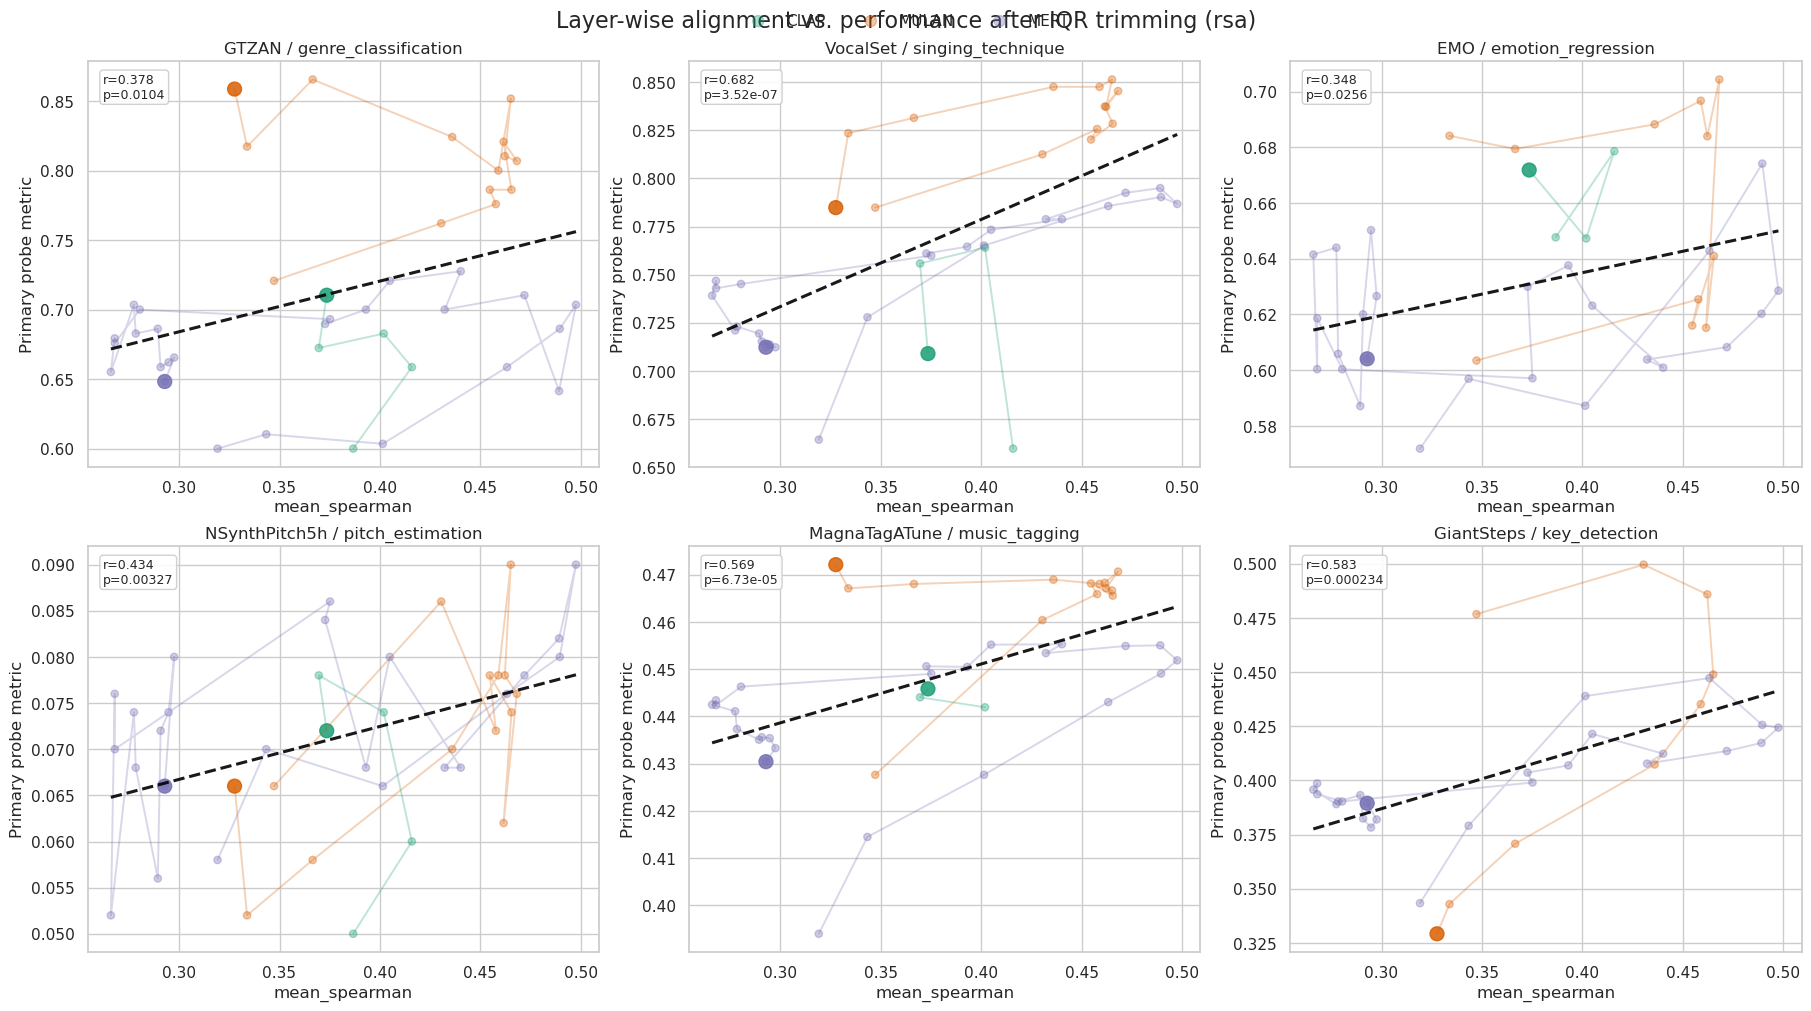

In [6]:
display(Markdown('### Layer-wise correlation after outlier trimming'))

def _iqr_filter(frame, x_col='alignment_score', y_col='primary_metric_value', fence=1.5):
    if len(frame) < 8:
        return frame.copy()
    q1_x, q3_x = frame[x_col].quantile([0.25, 0.75])
    q1_y, q3_y = frame[y_col].quantile([0.25, 0.75])
    iqr_x = q3_x - q1_x
    iqr_y = q3_y - q1_y
    if iqr_x == 0 and iqr_y == 0:
        return frame.copy()
    mask_x = pd.Series(True, index=frame.index) if iqr_x == 0 else frame[x_col].between(q1_x - fence * iqr_x, q3_x + fence * iqr_x)
    mask_y = pd.Series(True, index=frame.index) if iqr_y == 0 else frame[y_col].between(q1_y - fence * iqr_y, q3_y + fence * iqr_y)
    return frame[mask_x & mask_y].copy()

trimmed_parts = []
trim_stats = []
for dataset_task in task_order:
    subset = plot_layerwise[plot_layerwise['dataset_task'] == dataset_task].copy()
    if len(subset) == 0:
        continue
    trimmed = _iqr_filter(subset)
    trim_stats.append({
        'dataset_task': dataset_task,
        'n_before': int(len(subset)),
        'n_after': int(len(trimmed)),
        'n_removed': int(len(subset) - len(trimmed)),
    })
    trimmed_parts.append(trimmed)

trimmed_layerwise = pd.concat(trimmed_parts, ignore_index=True) if trimmed_parts else plot_layerwise.iloc[0:0].copy()
display(pd.DataFrame(trim_stats))

corr_rows = []
if len(trimmed_layerwise) >= 3:
    pearson_all = pearsonr(trimmed_layerwise['alignment_score'], trimmed_layerwise['primary_metric_value'])
    spearman_all = spearmanr(trimmed_layerwise['alignment_score'], trimmed_layerwise['primary_metric_value'])
    corr_rows.append({
        'dataset_task': 'ALL_TASKS',
        'n_points': int(len(trimmed_layerwise)),
        'pearson_r': float(pearson_all.statistic),
        'pearson_p': float(pearson_all.pvalue),
        'spearman_rho': float(spearman_all.statistic),
        'spearman_p': float(spearman_all.pvalue),
    })
for dataset_task in task_order:
    subset = trimmed_layerwise[trimmed_layerwise['dataset_task'] == dataset_task]
    if len(subset) < 3:
        continue
    pearson_task = pearsonr(subset['alignment_score'], subset['primary_metric_value'])
    spearman_task = spearmanr(subset['alignment_score'], subset['primary_metric_value'])
    corr_rows.append({
        'dataset_task': dataset_task,
        'n_points': int(len(subset)),
        'pearson_r': float(pearson_task.statistic),
        'pearson_p': float(pearson_task.pvalue),
        'spearman_rho': float(spearman_task.statistic),
        'spearman_p': float(spearman_task.pvalue),
    })
display(pd.DataFrame(corr_rows))

fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True)
axes = axes.ravel()
for ax, dataset_task in zip(axes, task_order):
    subset = trimmed_layerwise[trimmed_layerwise['dataset_task'] == dataset_task].copy().sort_values(['model_name', 'layer_order'])
    for model_name in model_order:
        model_subset = subset[subset['model_name'] == model_name]
        if len(model_subset) == 0:
            continue
        ax.plot(
            model_subset['alignment_score'],
            model_subset['primary_metric_value'],
            color=palette[model_name],
            linewidth=1.4,
            alpha=0.28,
        )
        ax.scatter(
            model_subset['alignment_score'],
            model_subset['primary_metric_value'],
            color=palette[model_name],
            s=np.where(model_subset['is_final'], 100, 28),
            alpha=np.where(model_subset['is_final'], 0.85, 0.35),
            label=model_name.upper(),
        )
    if len(subset) >= 3:
        x = subset['alignment_score'].to_numpy()
        y = subset['primary_metric_value'].to_numpy()
        slope, intercept = np.polyfit(x, y, deg=1)
        x_line = np.linspace(float(np.min(x)), float(np.max(x)), 100)
        y_line = slope * x_line + intercept
        pearson_task = pearsonr(x, y)
        ax.plot(x_line, y_line, color='black', linestyle='--', linewidth=2.2, alpha=0.9)
        ax.text(
            0.03,
            0.97,
            f"r={pearson_task.statistic:.3f}\np={pearson_task.pvalue:.3g}",
            transform=ax.transAxes,
            ha='left',
            va='top',
            fontsize=9,
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='0.8', alpha=0.9),
        )
    ax.set_title(dataset_task)
    ax.set_xlabel(score_label)
    ax.set_ylabel('Primary probe metric')

handles, labels = axes[0].get_legend_handles_labels()
unique = dict(zip(labels, handles))
if unique:
    fig.legend(unique.values(), unique.keys(), loc='upper center', ncol=3, frameon=False)
fig.suptitle(f'Layer-wise alignment vs. performance after IQR trimming ({ALIGNMENT_KIND})', fontsize=16)
plt.show()

### Best-aligned embedding only

,dataset_task,model_name,representation_name,alignment_score,primary_metric_value
0,GTZAN / genre_classification,clap,layer_02,0.415881,0.658621
1,GTZAN / genre_classification,mulan,layer_06,0.468153,0.806897
2,GTZAN / genre_classification,mert,layer_05,0.497579,0.703448
3,VocalSet / singing_technique,clap,layer_02,0.415881,0.659576
4,VocalSet / singing_technique,mulan,layer_06,0.468153,0.845439
5,VocalSet / singing_technique,mert,layer_05,0.497579,0.786764
6,EMO / emotion_regression,clap,layer_02,0.415881,0.678567
7,EMO / emotion_regression,mulan,layer_06,0.468153,0.704331
8,EMO / emotion_regression,mert,layer_05,0.497579,0.628515
9,NSynthPitch5h / pitch_estimation,clap,layer_02,0.415881,0.060000


,dataset_task,n_points,pearson_r,pearson_p,spearman_rho,spearman_p
0,ALL_TASKS,17,0.043044,0.869706,0.090697,0.729204
1,GTZAN / genre_classification,3,0.443279,0.707630,0.500000,0.666667
2,VocalSet / singing_technique,3,0.779184,0.431268,0.500000,0.666667
3,EMO / emotion_regression,3,-0.519637,0.652134,-0.500000,0.666667
4,NSynthPitch5h / pitch_estimation,3,0.992617,0.077409,1.000000,0.000000
5,MagnaTagATune / music_tagging,3,0.536051,0.639831,0.500000,0.666667
6,GiantSteps / key_detection,2,-1.000000,1.000000,-1.000000,NaN


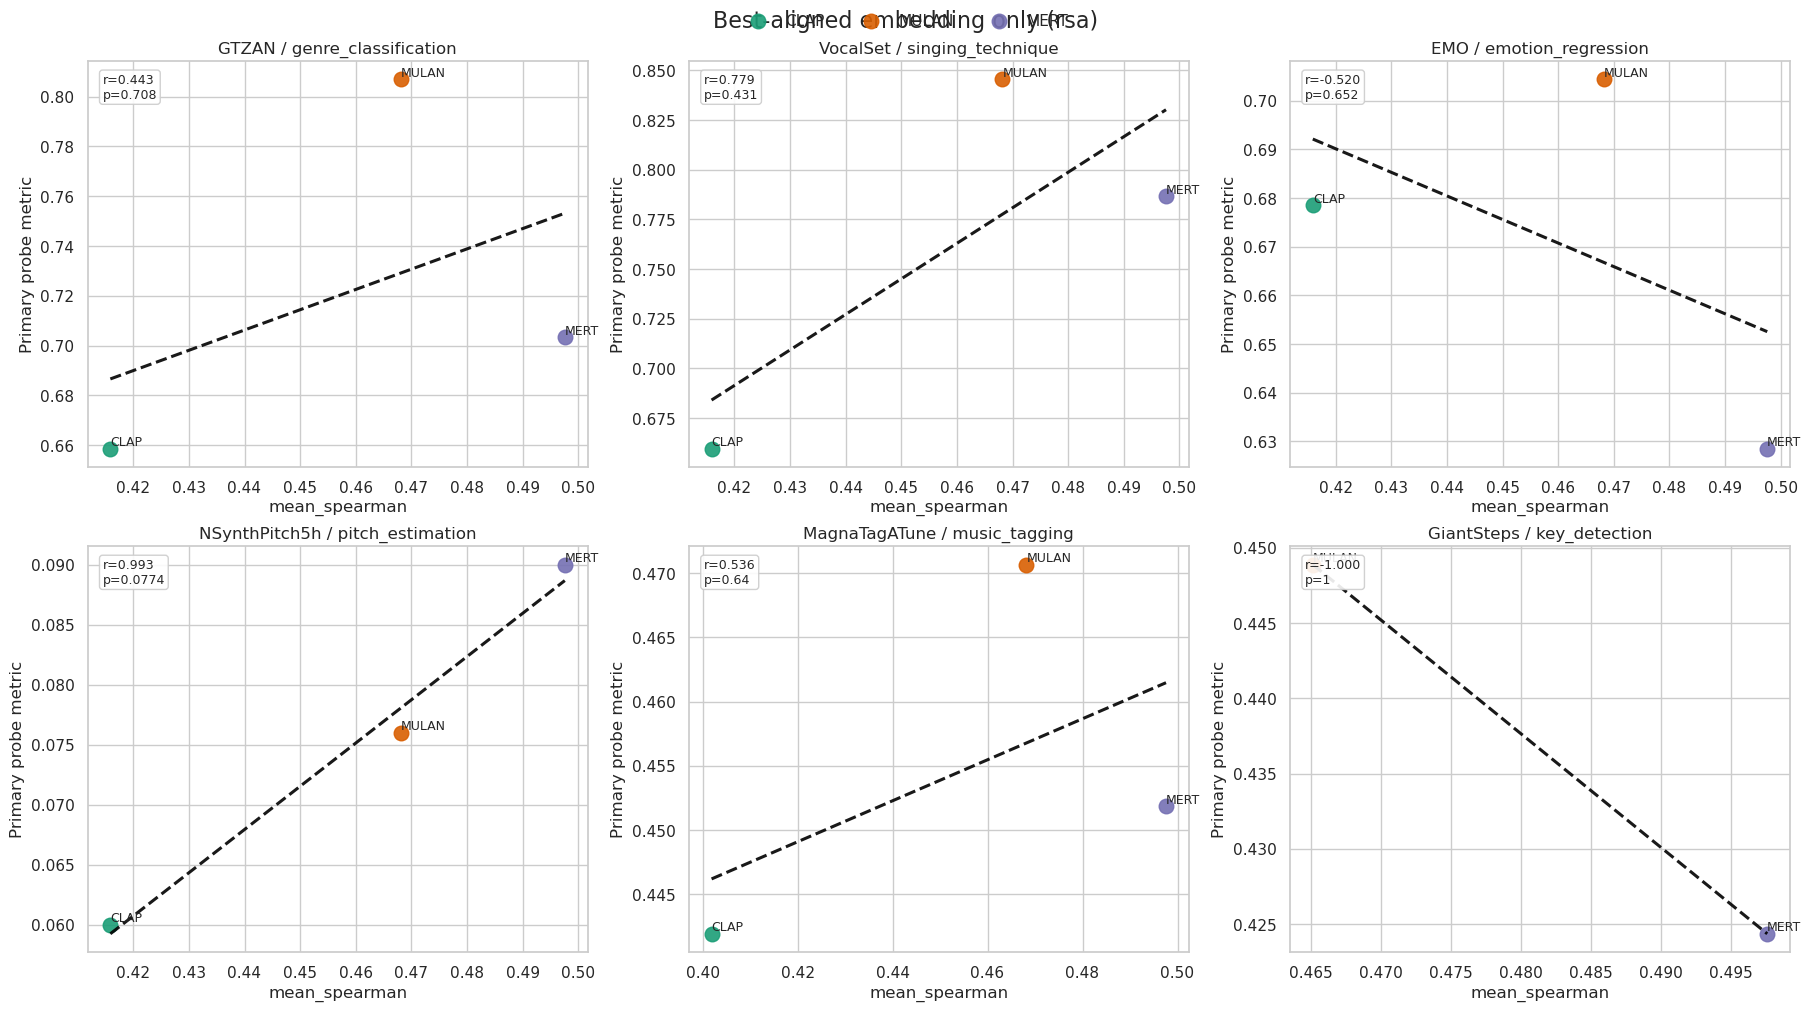

In [7]:
display(Markdown('### Best-aligned embedding only'))

best_aligned_points = (
    trimmed_layerwise.sort_values(
        ['dataset_task', 'model_name', 'alignment_score', 'primary_metric_value', 'layer_order'],
        ascending=[True, True, False, False, True],
    )
    .groupby(['dataset_task', 'model_name'], as_index=False, observed=True)
    .first()
)
display(best_aligned_points[['dataset_task', 'model_name', 'representation_name', 'alignment_score', 'primary_metric_value']])

corr_rows = []
if len(best_aligned_points) >= 3:
    pearson_all = pearsonr(best_aligned_points['alignment_score'], best_aligned_points['primary_metric_value'])
    spearman_all = spearmanr(best_aligned_points['alignment_score'], best_aligned_points['primary_metric_value'])
    corr_rows.append({
        'dataset_task': 'ALL_TASKS',
        'n_points': int(len(best_aligned_points)),
        'pearson_r': float(pearson_all.statistic),
        'pearson_p': float(pearson_all.pvalue),
        'spearman_rho': float(spearman_all.statistic),
        'spearman_p': float(spearman_all.pvalue),
    })
for dataset_task in task_order:
    subset = best_aligned_points[best_aligned_points['dataset_task'] == dataset_task]
    if len(subset) < 2:
        continue
    pearson_task = pearsonr(subset['alignment_score'], subset['primary_metric_value'])
    spearman_task = spearmanr(subset['alignment_score'], subset['primary_metric_value'])
    corr_rows.append({
        'dataset_task': dataset_task,
        'n_points': int(len(subset)),
        'pearson_r': float(pearson_task.statistic),
        'pearson_p': float(pearson_task.pvalue),
        'spearman_rho': float(spearman_task.statistic),
        'spearman_p': float(spearman_task.pvalue),
    })
display(pd.DataFrame(corr_rows))

fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True)
axes = axes.ravel()
for ax, dataset_task in zip(axes, task_order):
    subset = best_aligned_points[best_aligned_points['dataset_task'] == dataset_task].copy().sort_values(['model_name'])
    for model_name in model_order:
        model_subset = subset[subset['model_name'] == model_name]
        if len(model_subset) == 0:
            continue
        ax.scatter(
            model_subset['alignment_score'],
            model_subset['primary_metric_value'],
            color=palette[model_name],
            s=110,
            alpha=0.9,
            label=model_name.upper(),
        )
        for _, row in model_subset.iterrows():
            ax.text(row['alignment_score'], row['primary_metric_value'], model_name.upper(), fontsize=9, ha='left', va='bottom')
    if len(subset) >= 2:
        x = subset['alignment_score'].to_numpy()
        y = subset['primary_metric_value'].to_numpy()
        slope, intercept = np.polyfit(x, y, deg=1)
        x_line = np.linspace(float(np.min(x)), float(np.max(x)), 100)
        y_line = slope * x_line + intercept
        pearson_task = pearsonr(x, y)
        ax.plot(x_line, y_line, color='black', linestyle='--', linewidth=2.2, alpha=0.9)
        ax.text(
            0.03,
            0.97,
            f"r={pearson_task.statistic:.3f}\np={pearson_task.pvalue:.3g}",
            transform=ax.transAxes,
            ha='left',
            va='top',
            fontsize=9,
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='0.8', alpha=0.9),
        )
    ax.set_title(dataset_task)
    ax.set_xlabel(score_label)
    ax.set_ylabel('Primary probe metric')

handles, labels = axes[0].get_legend_handles_labels()
unique = dict(zip(labels, handles))
if unique:
    fig.legend(unique.values(), unique.keys(), loc='upper center', ncol=3, frameon=False)
fig.suptitle(f'Best-aligned embedding only ({ALIGNMENT_KIND})', fontsize=16)
plt.show()

### Best-aligned embedding only without outlier trimming

,dataset_task,model_name,representation_name,alignment_score,primary_metric_value
0,GTZAN / genre_classification,clap,layer_02,0.415881,0.658621
1,GTZAN / genre_classification,mulan,layer_06,0.468153,0.806897
2,GTZAN / genre_classification,mert,layer_05,0.497579,0.703448
3,VocalSet / singing_technique,clap,layer_02,0.415881,0.659576
4,VocalSet / singing_technique,mulan,layer_06,0.468153,0.845439
5,VocalSet / singing_technique,mert,layer_05,0.497579,0.786764
6,EMO / emotion_regression,clap,layer_02,0.415881,0.678567
7,EMO / emotion_regression,mulan,layer_06,0.468153,0.704331
8,EMO / emotion_regression,mert,layer_05,0.497579,0.628515
9,NSynthPitch5h / pitch_estimation,clap,layer_02,0.415881,0.060000


,dataset_task,n_points,pearson_r,pearson_p,spearman_rho,spearman_p
0,ALL_TASKS,18,0.139642,0.580511,0.131148,0.603957
1,GTZAN / genre_classification,3,0.443279,0.707630,0.500000,0.666667
2,VocalSet / singing_technique,3,0.779184,0.431268,0.500000,0.666667
3,EMO / emotion_regression,3,-0.519637,0.652134,-0.500000,0.666667
4,NSynthPitch5h / pitch_estimation,3,0.992617,0.077409,1.000000,0.000000
5,MagnaTagATune / music_tagging,3,0.831359,0.375127,0.500000,0.666667
6,GiantSteps / key_detection,3,0.772019,0.438494,0.500000,0.666667


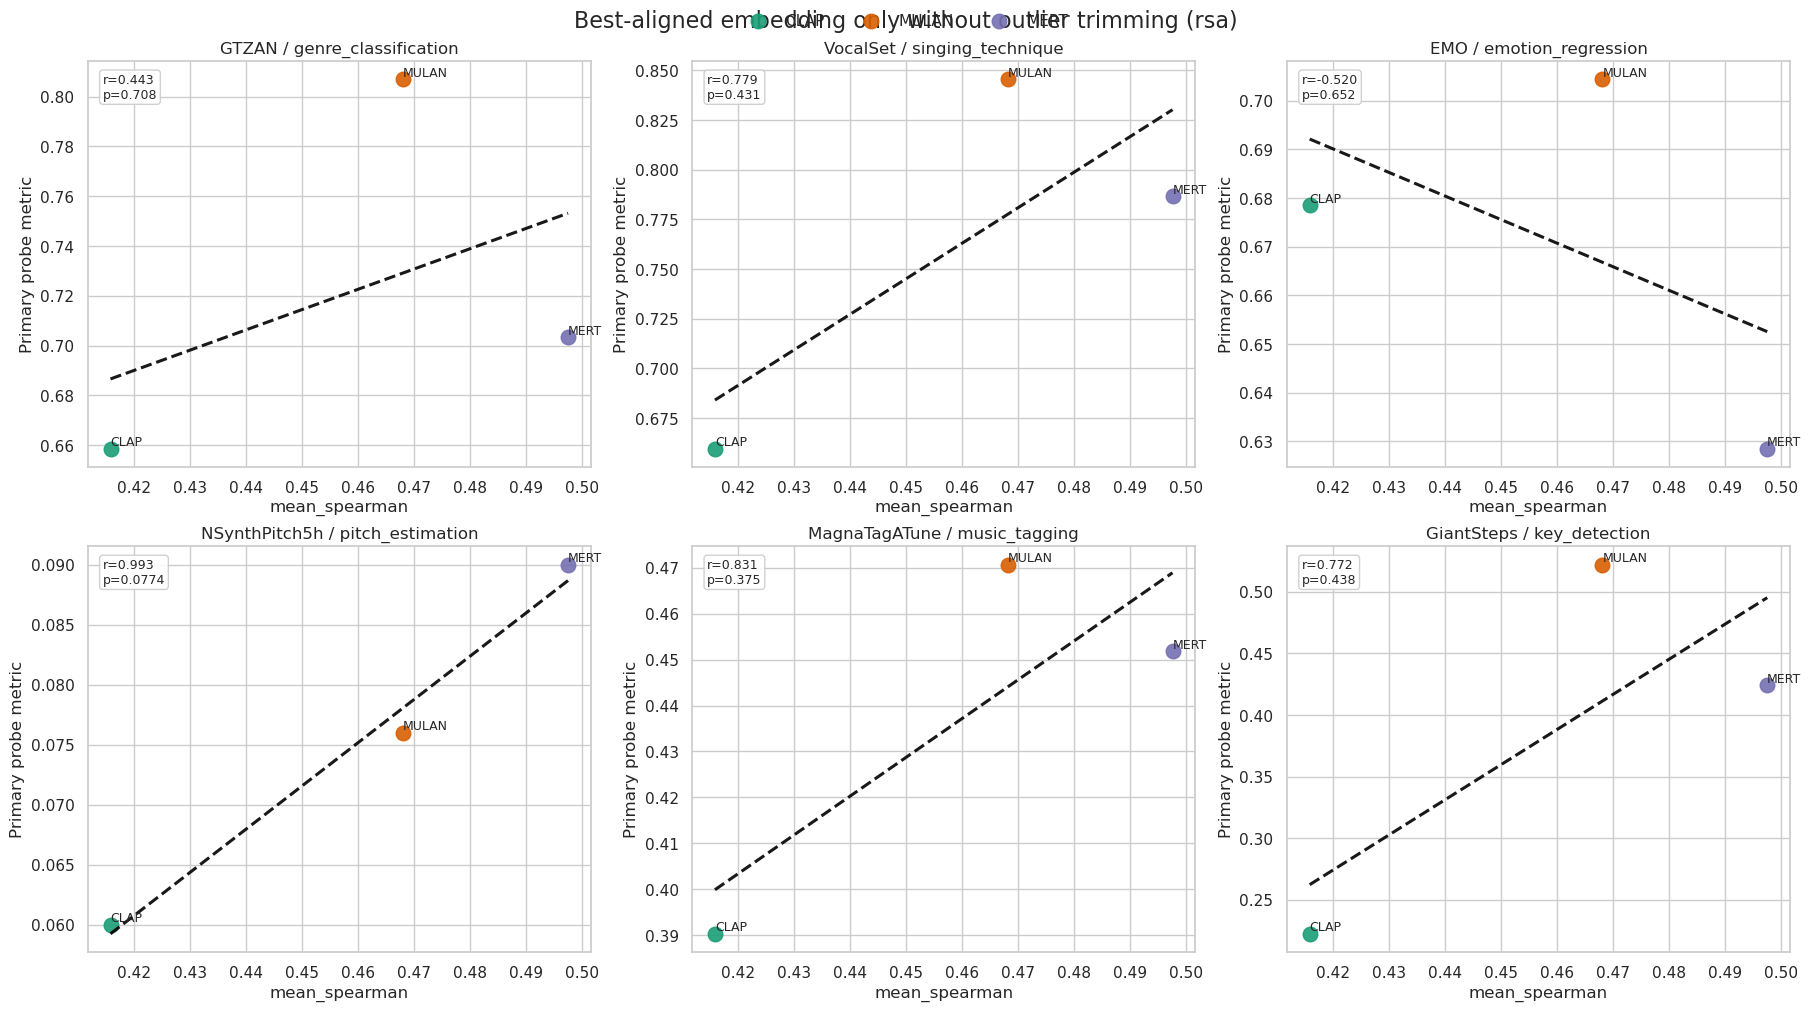

In [8]:
display(Markdown('### Best-aligned embedding only without outlier trimming'))

best_aligned_points_raw = (
    plot_layerwise.sort_values(
        ['dataset_task', 'model_name', 'alignment_score', 'primary_metric_value', 'layer_order'],
        ascending=[True, True, False, False, True],
    )
    .groupby(['dataset_task', 'model_name'], as_index=False, observed=True)
    .first()
)
display(best_aligned_points_raw[['dataset_task', 'model_name', 'representation_name', 'alignment_score', 'primary_metric_value']])

corr_rows = []
if len(best_aligned_points_raw) >= 3:
    pearson_all = pearsonr(best_aligned_points_raw['alignment_score'], best_aligned_points_raw['primary_metric_value'])
    spearman_all = spearmanr(best_aligned_points_raw['alignment_score'], best_aligned_points_raw['primary_metric_value'])
    corr_rows.append({
        'dataset_task': 'ALL_TASKS',
        'n_points': int(len(best_aligned_points_raw)),
        'pearson_r': float(pearson_all.statistic),
        'pearson_p': float(pearson_all.pvalue),
        'spearman_rho': float(spearman_all.statistic),
        'spearman_p': float(spearman_all.pvalue),
    })
for dataset_task in task_order:
    subset = best_aligned_points_raw[best_aligned_points_raw['dataset_task'] == dataset_task]
    if len(subset) < 2:
        continue
    pearson_task = pearsonr(subset['alignment_score'], subset['primary_metric_value'])
    spearman_task = spearmanr(subset['alignment_score'], subset['primary_metric_value'])
    corr_rows.append({
        'dataset_task': dataset_task,
        'n_points': int(len(subset)),
        'pearson_r': float(pearson_task.statistic),
        'pearson_p': float(pearson_task.pvalue),
        'spearman_rho': float(spearman_task.statistic),
        'spearman_p': float(spearman_task.pvalue),
    })
display(pd.DataFrame(corr_rows))

fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True)
axes = axes.ravel()
for ax, dataset_task in zip(axes, task_order):
    subset = best_aligned_points_raw[best_aligned_points_raw['dataset_task'] == dataset_task].copy().sort_values(['model_name'])
    for model_name in model_order:
        model_subset = subset[subset['model_name'] == model_name]
        if len(model_subset) == 0:
            continue
        ax.scatter(
            model_subset['alignment_score'],
            model_subset['primary_metric_value'],
            color=palette[model_name],
            s=110,
            alpha=0.9,
            label=model_name.upper(),
        )
        for _, row in model_subset.iterrows():
            ax.text(row['alignment_score'], row['primary_metric_value'], model_name.upper(), fontsize=9, ha='left', va='bottom')
    if len(subset) >= 2:
        x = subset['alignment_score'].to_numpy()
        y = subset['primary_metric_value'].to_numpy()
        slope, intercept = np.polyfit(x, y, deg=1)
        x_line = np.linspace(float(np.min(x)), float(np.max(x)), 100)
        y_line = slope * x_line + intercept
        pearson_task = pearsonr(x, y)
        ax.plot(x_line, y_line, color='black', linestyle='--', linewidth=2.2, alpha=0.9)
        ax.text(
            0.03,
            0.97,
            f"r={pearson_task.statistic:.3f}\np={pearson_task.pvalue:.3g}",
            transform=ax.transAxes,
            ha='left',
            va='top',
            fontsize=9,
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='0.8', alpha=0.9),
        )
    ax.set_title(dataset_task)
    ax.set_xlabel(score_label)
    ax.set_ylabel('Primary probe metric')

handles, labels = axes[0].get_legend_handles_labels()
unique = dict(zip(labels, handles))
if unique:
    fig.legend(unique.values(), unique.keys(), loc='upper center', ncol=3, frameon=False)
fig.suptitle(f'Best-aligned embedding only without outlier trimming ({ALIGNMENT_KIND})', fontsize=16)
plt.show()